# [CS303]Practice 3 - Uninformed Search
## 1. Reqirement

1. Build a weighted directed graph from a text description (adjacency dictionary).
2. Implement **BFS** (FIFO), **DFS** (LIFO).
3. Enforce the **alphabetical tie-break** rule and the correct stop condition.
4. Use Python **generators (`yield`)** to step through the frontier.


| Algorithm | Frontier | Expansion rule |
|---|---|---|
| **BFS** | FIFO queue | shallowest node first | 
| **DFS** | LIFO stack | deepest node first |


#### **Two rules**
- **Tie-break:** when several nodes are tied (same depth / cost / stack level), pop them **alphabetically**.
- **Mark visited at enqueue time** (not when popped), so a node is never enqueued twice.

#### **Practice Deadline and Checking Policy**

The score for this practice is determined by **when you have your work checked during your lab session**. Please follow the schedule of your own lab group.

| Lab Group     | Full Credit (100%)           | Late Check (50%)        | After the 50% Deadline |
| ------------- | ---------------------------- | ----------------------- | ---------------------- |
| **Wednesday** | Sep. 23 or Sep. 30           | **Oct. 10 or Oct. 14**  | 0%                     |
| **Thursday**  | Sep. 24 or **Oct. 8**        | **Oct. 15**             | 0%                     |
| **Friday**    | **Sep. 20** or **Oct. 9**    | **Oct. 16**             | 0%                     |

You have **two lab sessions to complete and have your work checked for full credit (100%)**. If you miss both sessions, you can still have your work checked at the designated late-check session, but you will receive only **50% of the points**. Any check after the 50% deadline will receive **0 points**.

**Holiday schedule adjustment:** The **Wednesday group has one more chance of late check than the Thursday and Friday groups**. 

**Important:** The score is determined by the **date of your in-person check**.

#### **What will be tested**
* That you understand every line of your code, not just copy from somewhere 
* That your program compiles correctly
* Correctness of the program logic 
* That the result is obtained in a reasonable time 

## 2. Graph Data (embedded, with node positions)

#### **Format:** 
First line: node names (**first token = start, last token = end**);  
Second line: number of edges;   
Then `u v weight` lines;
Last line:`x1 y1 x2 y2 ...` layout positions, one pair per node.


> ⚠️ **Common mistake:** in Case 1 the start is `S` and the end is **`H`** (the last token).


In [1]:
import heapq
import time
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import clear_output

# ---- Test case 1: S -> H (13 edges) ----
CASE1 = """S A B C D E F G H
13
S A 3
A D 3
S B 6
S C 2
B D 4
B G 9
B E 2
D F 5
E F 6
E H 5
F G 5
H G 8
C E 1
-1 0 0 1 0 0 0 -1 1 1 1 -1 1.8 1 2.5 0 1.8 -1
"""

# ---- Test case 2: A -> B (15 edges, Romanian-style) ----
CASE2 = """A T Z O L D S R C F P B
15
A Z 75
A S 140
A T 118
T L 70
Z O 71
O S 151
L D 145
D C 120
S R 80
S F 99
R P 97
R C 146
C P 138
F B 211
P B 101
-1.9 0.9 -1.9 -0.3 -1.8 1.5 -1.6 2.1 -1 -0.7 -0.9 -1.6 -0.7 0.6 -0.4 -0.2 0 -1.8 0.6 0.3 0.75 -0.8 2 -1.5
"""

def load_graph(text):
    """Parse the embedded text.
    Returns (Graph, start, end, position). Graph[u] = [(v, weight), ...]"""
    lines = text.strip().splitlines()
    nodes = lines[0].split()
    M = int(lines[1])
    Graph = {n: [] for n in nodes}
    for i in range(M):
        u, v, w = lines[2 + i].split()
        Graph[u].append((v, int(w)))
    pos_vals = lines[2 + M].split()
    position = {}
    for i, n in enumerate(nodes):
        position[n] = (float(pos_vals[2 * i]), float(pos_vals[2 * i + 1]))
    return Graph, nodes[0], nodes[-1], position

G1, start1, end1, pos1 = load_graph(CASE1)
G2, start2, end2, pos2 = load_graph(CASE2)
print(f"Case 1: {start1} -> {end1}  ({len(G1)} nodes, {sum(len(v) for v in G1.values())} edges)")
print(f"Case 2: {start2} -> {end2}  ({len(G2)} nodes, {sum(len(v) for v in G2.values())} edges)")

Case 1: S -> H  (9 nodes, 13 edges)
Case 2: A -> B  (12 nodes, 15 edges)


## 3. Animation drawing function (given)

Node colors: **white** = undiscovered, **brown** = in the frontier, **gray** = expanded.


In [2]:
WHITE, BROWN, GRAY = (1,1,1), (0.5,0.25,0), (0.5,0.5,0.5)

def draw_frame(Graph, position, frontier, expanded):
    """Draw one frame: frontier=brown, expanded=gray, undiscovered=white."""
    G = nx.DiGraph()
    for u in Graph:
        for v, w in Graph[u]:
            G.add_edge(u, v, weight=w)
    colors = []
    for n in G.nodes:
        if n in expanded:
            colors.append(GRAY)
        elif n in frontier:
            colors.append(BROWN)
        else:
            colors.append(WHITE)
    edge_labels = {(u, v): w for u in Graph for v, w in Graph[u]}
    plt.figure(figsize=(6.5, 4))
    nx.draw(G, position, with_labels=True, node_color=colors,
            node_size=900, edge_color="gray", font_weight="bold")
    nx.draw_networkx_edge_labels(G, position, edge_labels=edge_labels)
    plt.axis("off")
    plt.show()
    plt.close()

## 4. Yield Crash Course (for Python beginners)

You are new to Python, so read this before writing BFS/DFS.

### 4.1 One sentence
A function that contains `yield` is **not** a normal function — calling it does **not**
run the whole function. It returns a **generator**: an object that runs *a little at a time*.

### 4.2 Small example — it pauses and resumes


In [3]:
def count_to_3():
    print("  -> about to give 1")
    yield 1
    print("  -> resuming, about to give 2")
    yield 2
    print("  -> resuming, about to give 3")
    yield 3

gen = count_to_3()   # NOTHING prints yet — the function body has not run!



In [4]:
next(gen)   # runs until the first  yield, returns 1

  -> about to give 1


1

In [5]:
next(gen)   # continues from where it stopped, returns 2

  -> resuming, about to give 2


2

In [6]:
next(gen)   # returns 3

  -> resuming, about to give 3


3

In [7]:
next(gen) # StopIteration

StopIteration: 

Run four times on `next(gen)` and watch
how the `print` lines appear one at a time. The function freezes at each `yield`.

### 4.3 yield vs return

| | `return` | `yield` |
|---|---|---|
| how many times | only once | many times |
| function state | ends, variables destroyed | **freezes**, resumes next time |
| what you get | the value immediately | a generator, must `next()` to read it |

### 4.4 Why this lab needs yield
BFS/DFS must draw **one frame at a time**. If the algorithm ran to completion
there would be no chance to draw in between. `yield list(queue)` hands the current
frontier to the animation, the animation draws one frame, then `next(gen)` makes the
algorithm take **one more step** until the next `yield`.

> **Pitfall 1:** always `yield list(queue)` — a *copy*. If you `yield queue` directly,
> the animation holds a reference to the same list, and every frame changes together.
>
> **Pitfall 2:** when the generator is exhausted, `next()` raises `StopIteration`.
> A `for` loop handles this for you automatically:
>
> ```python
> for frontier in BFS(Graph, "S", "H"):
>     draw(frontier)
> ```


## 5. TODO — BFS (FIFO)

**Rules**
- FIFO: expand the node that has waited the longest.
- Neighbors are explored **alphabetically** (`sorted(Graph[node])`).
- Mark `visited` when enqueued.
- **Yield contract:** yield a **copy** of the queue (`list(queue)`) right **before** every pop,
  and once more **after** the goal is popped.


In [8]:
def BFS(Graph, start, end):
    """Breadth-First Search — FIFO queue."""
    queue = [start]
    visited = {start}

    while queue:
        yield list(queue)        # right before popping

        node = queue.pop(0)                  # FIFO: pop the front

        if node == end:
            yield list(queue); break

        # TODO:
    pass

## 6. TODO — DFS (LIFO)

Same signature and rules as BFS, but LIFO. To pop neighbors **alphabetically**,
push them in **reverse alphabetical order** so the smallest name ends up on top.


In [9]:
def DFS(Graph, start, end):
    """Depth-First Search — LIFO stack."""
    stack = [start]
    visited = {start}

    while stack:
        yield list(stack)        # right before popping

        node = stack.pop()                   # LIFO: pop the top

        if node == end:
            yield list(stack); break

        # TODO:
    pass

## 7. Run the Search (with animation)

Each call clears the output and redraws the graph for every frame.
After you fill the TODOs, uncomment one call below.


In [10]:
def run_search(algo, text, label, animate=True, delay=0.5, step=False):
    Graph, start, end, position = load_graph(text)
    gen = algo(Graph, start, end)

    frontier = next(gen)
    brown = set(frontier)        # nodes currently in the frontier
    expanded = []

    def paint(f):
        for n in Graph:
            if n in f:
                if n not in brown and n not in expanded:
                    brown.add(n)
            else:
                if n in brown:
                    brown.discard(n)
                    expanded.append(n)

    paint(frontier)
    frame_no = 1
    while True:
        if animate:
            clear_output(wait=True)
            print(f"--- {label} | {start} -> {end} | frame {frame_no:02d} ---")
            print(f"  frame {frame_no:02d}:", frontier)
            draw_frame(Graph, position, brown, expanded)
            if step:
                ans = input("press Enter for the next frame (q + Enter to stop) >> ")
                if ans.strip().lower() == "q":
                    break
            elif delay:
                time.sleep(delay)
        try:
            frontier = next(gen)
        except StopIteration:
            break
        paint(frontier)
        frame_no += 1
    if animate:
        clear_output(wait=True)
        print(f"--- {label} | {start} -> {end} | DONE ---")
        draw_frame(Graph, position, set(), expanded)
    print("expansion order:", expanded)

--- BFS CASE1 step | S -> H | DONE ---


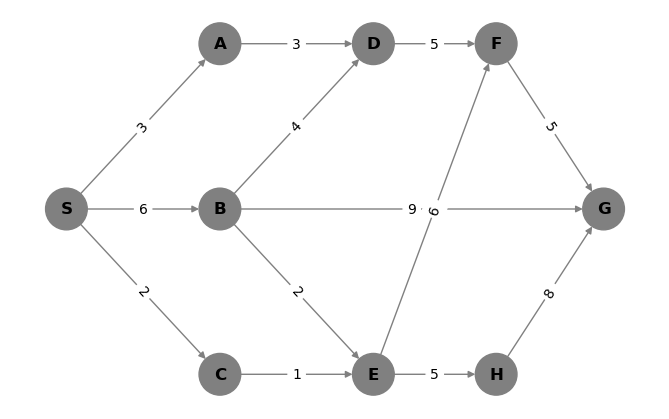

expansion order: ['S', 'A', 'B', 'C', 'D', 'E', 'G', 'F', 'H']


In [12]:
# After implementing the TODOs, uncomment and run (animation will play):
# run_search(BFS, CASE1, "BFS CASE1 step", delay=0, step=True)

--- BFS CASE2 step | A -> B | DONE ---


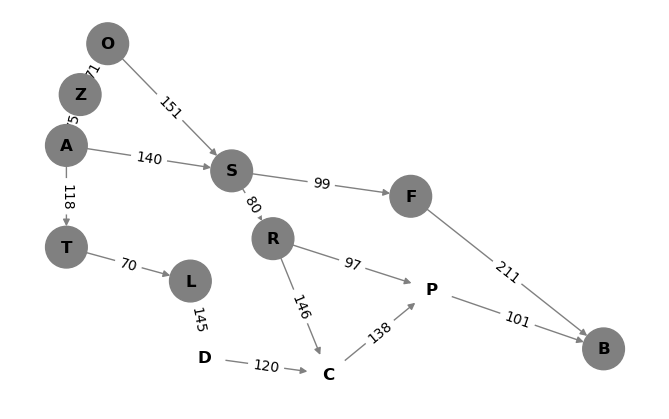

expansion order: ['A', 'S', 'T', 'Z', 'F', 'R', 'L', 'O', 'B']


In [13]:
# run_search(BFS, CASE2, "BFS CASE2 step", delay=0, step=True)

--- DFS CASE1 step | S -> H | DONE ---


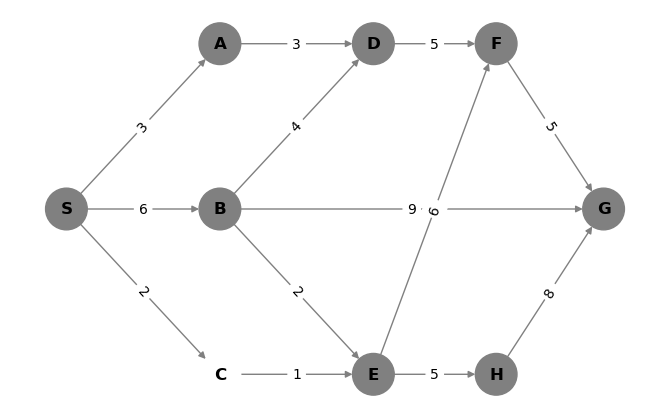

expansion order: ['S', 'A', 'D', 'F', 'G', 'B', 'E', 'H']


In [16]:
# run_search(DFS, CASE1, "DFS CASE1 step", delay=0, step=True)

--- DFS CASE2 step | A -> B | DONE ---


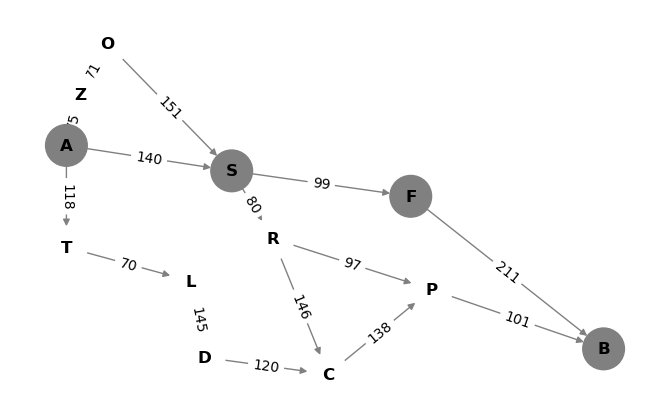

expansion order: ['A', 'S', 'F', 'B']


In [17]:
# run_search(DFS, CASE2, "DFS CASE2 step", delay=0, step=True)

## 8. Expected Output (Self-Check)

Run your TODOs and compare against these sequences.

**Case 1 — `S` → `H`**
| Algorithm | Expansion order |
|---|---|
| BFS | `S, A, B, C, D, E, G, F, H` |
| DFS | `S, A, D, F, G, B, E, H` |


**Case 2 — `A` → `B`**
| Algorithm | Expansion order |
|---|---|
| BFS | `A, S, T, Z, F, R, L, O, B` |
| DFS | `A, S, F, B` |

